<a href="https://colab.research.google.com/github/nikita082000/DTEY/blob/%D0%9C%D0%9D/%D0%9B%D0%A03_%D0%9D%D1%96%D0%BA%D0%B8%D1%82%D0%B5%D0%BD%D0%BA%D0%BE_4_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота 3. Машинне навчання
## Регресія: прогнозування вартості нерухомості

**Мета роботи:** виконати первинний аналіз даних, побудувати кілька моделей регресії, оцінити їхню якість та виконати підбір гіперпараметрів для моделі Random Forest.

### Датасет
Можна використати один із двох способів завантаження даних:

1. Завантажити файл з Google Drive:
https://drive.google.com/file/d/1u_-3X05st6uvrgQB1qNLyE8a7QjTJjvd/view?usp=sharing

2. Завантажити датасет з Kaggle:
https://www.kaggle.com/datasets/prokshitha/home-value-insights

> Посилання та вміст датасету на зовнішніх платформах можуть змінюватися.

## 1. Імпорт бібліотек
Імпортуйте бібліотеки, необхідні для роботи з даними, візуалізації та числових обчислень.

In [1]:
# Ваш код:
# Імпортуйте pandas, numpy, matplotlib.pyplot, seaborn та інші потрібні бібліотеки.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns



## 2. Завантаження даних
Завантажте файл двома способами.

### Варіант 1. Завантаження файлу з комп’ютера
Завантажте CSV-файл у середовище Colab.

In [2]:
# Ваш код:
# Завантажте файл і збережіть дані у DataFrame `df`.

from google.colab import files

uploaded = files.upload()



Saving house_price_regression_dataset.csv to house_price_regression_dataset.csv


In [3]:
df = pd.read_csv("house_price_regression_dataset.csv")

### Варіант 2. Завантаження датасету з Kaggle
Завантажте датасет безпосередньо з Kaggle та прочитайте CSV-файл у DataFrame `df`.

In [4]:
# Ваш код:
# Завантажте датасет з Kaggle та створіть DataFrame `df`.
!pip install -q kagglehub

import kagglehub
import os

path = kagglehub.dataset_download(
    "prokshitha/home-value-insights"
)

df = pd.read_csv(
    os.path.join(path, "house_price_regression_dataset.csv")
)





100%|██████████| 26.4k/26.4k [00:00<00:00, 15.2MB/s]

Extracting files...


In [5]:
df.head()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


## 3. Опис ознак датасету

- **Square_Footage** — загальна житлова площа будинку.
- **Num_Bedrooms** — кількість спалень.
- **Num_Bathrooms** — кількість ванних кімнат.
- **Year_Built** — рік побудови будинку.
- **Lot_Size** — розмір земельної ділянки.
- **Garage_Size** — розмір гаража або кількість паркомісць.
- **Neighborhood_Quality** — оцінка якості району.
- **House_Price** — ціна будинку, цільова змінна.

## 4. Первинний аналіз даних

### Завдання 1. Перегляд даних
Виведіть перші рядки датасету та перегляньте його структуру.

In [8]:
# Ваш код:
# Виведіть кілька перших рядків та загальну інформацію про DataFrame.

df.head()

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,2.623829e+05
1,4272,3,3,2016,4.753014,1,6,9.852609e+05
2,3592,1,2,2016,3.634823,0,9,7.779774e+05
3,966,1,2,1977,2.730667,1,8,2.296989e+05
4,4926,2,1,1993,4.699073,0,8,1.041741e+06


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Square_Footage        1000 non-null   int64  
 1   Num_Bedrooms          1000 non-null   int64  
 2   Num_Bathrooms         1000 non-null   int64  
 3   Year_Built            1000 non-null   int64  
 4   Lot_Size              1000 non-null   float64
 5   Garage_Size           1000 non-null   int64  
 6   Neighborhood_Quality  1000 non-null   int64  
 7   House_Price           1000 non-null   float64
dtypes: float64(2), int64(6)
memory usage: 62.6 KB


### Завдання 2. Перевірка дублікатів
Визначте кількість дубльованих рядків.

In [10]:
# Ваш код:
# Порахуйте кількість дублікатів.


print("Кількість дублікатів:", df.duplicated().sum())


Кількість дублікатів: 0


### Завдання 3. Перевірка пропущених значень
Визначте кількість пропущених значень у кожному стовпці.

In [12]:
# Ваш код:
# Виведіть кількість пропусків для кожної ознаки.


df.isna().sum()


,0
Square_Footage,0
Num_Bedrooms,0
Num_Bathrooms,0
Year_Built,0
Lot_Size,0
Garage_Size,0
Neighborhood_Quality,0
House_Price,0


### Завдання 4. Описова статистика
Виведіть основні статистичні характеристики числових ознак.

In [13]:
# Ваш код:
# Отримайте описову статистику датасету.


df.describe()


,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000,1.000000e+03
mean,2815.422000,2.990000,1.973000,1986.550000,2.778087,1.022000,5.615000,6.188610e+05
std,1255.514921,1.427564,0.820332,20.632916,1.297903,0.814973,2.887059,2.535681e+05
min,503.000000,1.000000,1.000000,1950.000000,0.506058,0.000000,1.000000,1.116269e+05
25%,1749.500000,2.000000,1.000000,1969.000000,1.665946,0.000000,3.000000,4.016482e+05
50%,2862.500000,3.000000,2.000000,1986.000000,2.809740,1.000000,6.000000,6.282673e+05
75%,3849.500000,4.000000,3.000000,2004.250000,3.923317,2.000000,8.000000,8.271413e+05
max,4999.000000,5.000000,3.000000,2022.000000,4.989303,2.000000,10.000000,1.108237e+06


## 5. Аналіз окремих ознак

### Завдання 5. Ознака `Neighborhood_Quality`
Виведіть частоти значень ознаки `Neighborhood_Quality`.

In [14]:
# Ваш код:
# Порахуйте кількість спостережень для кожного значення `Neighborhood_Quality`.


df["Neighborhood_Quality"].value_counts().sort_index()


,count
Neighborhood_Quality,
1,91
2,105
3,85
4,99
5,109
6,101
7,102
8,97
9,88


### Завдання 6. Візуалізація `Neighborhood_Quality`
Побудуйте діаграму розподілу значень цієї ознаки.

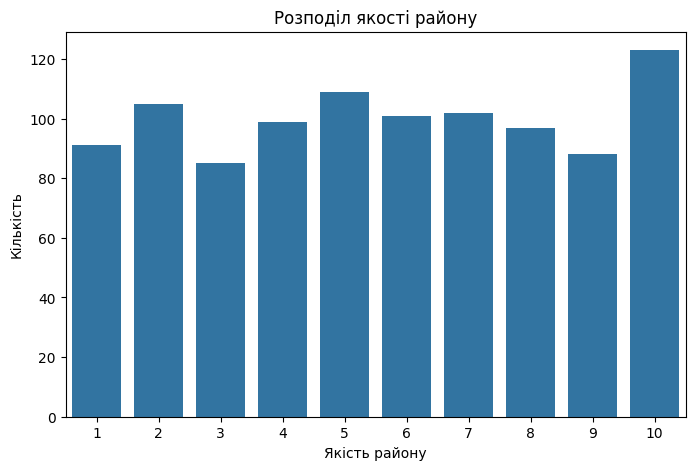

In [15]:
# Ваш код:
# Побудуйте countplot або іншу відповідну діаграму.


plt.figure(figsize=(8, 5))

sns.countplot(
    x="Neighborhood_Quality",
    data=df
)

plt.title("Розподіл якості району")
plt.xlabel("Якість району")
plt.ylabel("Кількість")

plt.show()


### Завдання 7. Ознака `Num_Bathrooms`
Виведіть частоти значень кількості ванних кімнат.

In [16]:
# Ваш код:
# Порахуйте кількість спостережень для кожного значення `Num_Bathrooms`.
df["Num_Bathrooms"].value_counts().sort_index()




,count
Num_Bathrooms,
1,350
2,327
3,323


### Завдання 8. Візуалізація `Num_Bathrooms`
Побудуйте діаграму розподілу кількості ванних кімнат.

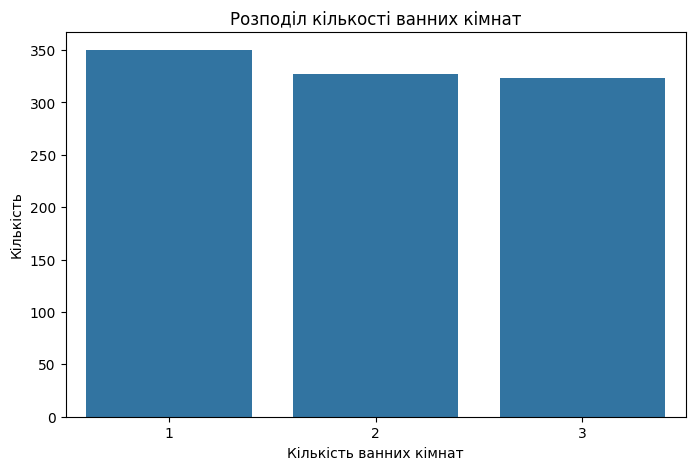

In [17]:
# Ваш код:
# Побудуйте відповідну діаграму.

plt.figure(figsize=(8, 5))

sns.countplot(
    x="Num_Bathrooms",
    data=df
)

plt.title("Розподіл кількості ванних кімнат")
plt.xlabel("Кількість ванних кімнат")
plt.ylabel("Кількість")

plt.show()



### Додаткове завдання
За потреби побудуйте попарні графіки числових ознак і коротко проаналізуйте можливі залежності.

In [ ]:
# Ваш код:
# Побудуйте pairplot або іншу попарну візуалізацію.





## 6. Кореляційний аналіз

### Завдання 9. Матриця кореляції
Побудуйте кореляційну матрицю для числових ознак та відобразіть її у вигляді теплової карти.

In [18]:
# Ваш код:
# Обчисліть кореляційну матрицю та побудуйте heatmap.

correlation = df.corr(numeric_only=True)

correlation



,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
Square_Footage,1.000000,-0.043564,-0.031584,-0.022392,0.089479,0.030593,-0.008357,0.991261
Num_Bedrooms,-0.043564,1.000000,0.022848,-0.015820,-0.009355,0.113761,-0.049024,0.014633
Num_Bathrooms,-0.031584,0.022848,1.000000,-0.021063,0.034923,0.024846,0.017585,-0.001862
Year_Built,-0.022392,-0.015820,-0.021063,1.000000,-0.061050,-0.025485,-0.009549,0.051967
Lot_Size,0.089479,-0.009355,0.034923,-0.061050,1.000000,0.002436,0.037630,0.160412
Garage_Size,0.030593,0.113761,0.024846,-0.025485,0.002436,1.000000,-0.011287,0.052133
Neighborhood_Quality,-0.008357,-0.049024,0.017585,-0.009549,0.037630,-0.011287,1.000000,-0.007770
House_Price,0.991261,0.014633,-0.001862,0.051967,0.160412,0.052133,-0.007770,1.000000


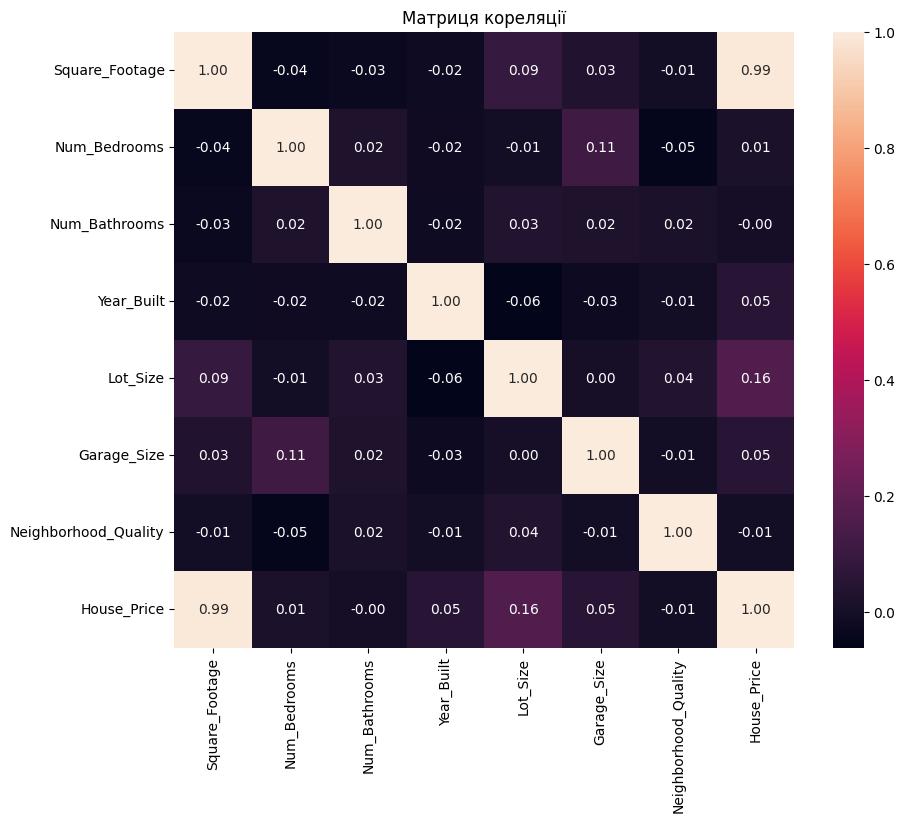

In [19]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f"
)

plt.title("Матриця кореляції")

plt.show()

### Завдання 10. Кореляція з цільовою змінною
Виведіть кореляцію кожної ознаки з `House_Price`, відсортувавши значення за спаданням.

In [20]:
# Ваш код:
# Виведіть кореляції ознак із `House_Price`.

correlation["House_Price"].drop("House_Price").sort_values(ascending=False)



,House_Price
Square_Footage,0.991261
Lot_Size,0.160412
Garage_Size,0.052133
Year_Built,0.051967
Num_Bedrooms,0.014633
Num_Bathrooms,-0.001862
Neighborhood_Quality,-0.007770


## 7. Побудова моделей регресії

### Завдання 11. Імпорт інструментів Scikit-learn
Імпортуйте засоби для:
- поділу вибірки;
- масштабування ознак;
- побудови Linear Regression, Ridge, Lasso, Random Forest та Gradient Boosting;
- створення Pipeline;
- обчислення R², MAE та MSE.

In [21]:
# Ваш код:
# Імпортуйте необхідні класи та функції зі scikit-learn.


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error


### Завдання 12. Формування `X` і `y`
Відокремте ознаки від цільової змінної `House_Price`.

In [22]:
# Ваш код:
# Створіть `X` та `y`.

X = df.drop("House_Price", axis=1)
y = df["House_Price"]



In [23]:
print(X.shape)
print(y.shape)

(1000, 7)
(1000,)


### Завдання 13. Поділ даних
Поділіть дані на навчальну і тестову вибірки у співвідношенні 80/20. Для відтворюваності використайте `random_state=42`.

In [24]:
# Ваш код:
# Створіть `X_train`, `X_test`, `y_train`, `y_test`.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)




In [25]:
print("Навчальна вибірка:", X_train.shape)
print("Тестова вибірка:", X_test.shape)

Навчальна вибірка: (800, 7)
Тестова вибірка: (200, 7)


### Завдання 14. Створення моделей
Створіть п’ять моделей:
1. Linear Regression;
2. Ridge;
3. Lasso;
4. Random Forest Regressor;
5. Gradient Boosting Regressor.

Для лінійних моделей використайте `Pipeline` зі `StandardScaler`. Для деревоподібних моделей масштабування не потрібне.

In [26]:
# Ваш код:
# Створіть словник або іншу структуру з п’ятьма моделями.
models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Ridge": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge())
    ]),

    "Lasso": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso())
    ]),

    "Random Forest": RandomForestRegressor(
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    )
}




### Завдання 15. Навчання та оцінювання моделей
Для кожної моделі:
- виконайте навчання на тренувальній вибірці;
- отримайте прогноз для тестової вибірки;
- обчисліть `R²`, `MAE`, `MSE`;
- збережіть результати для подальшого порівняння.

In [27]:
# Ваш код:
# Навчіть усі моделі, отримайте прогнози та метрики на тестовій вибірці.

results = []
predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)

    results.append([name, r2, mae, mse])



In [28]:
results_df = pd.DataFrame(
    results,
    columns=["Model", "R²", "MAE", "MSE"]
)

results_df

,Model,R²,MAE,MSE
0,Linear Regression,0.998426,8174.583600,1.014348e+08
1,Ridge,0.998410,8241.586911,1.024810e+08
2,Lasso,0.998426,8174.748374,1.014366e+08
3,Random Forest,0.993886,16114.289644,3.941317e+08
4,Gradient Boosting,0.996510,12305.217615,2.249656e+08


### Завдання 16. Графічне порівняння прогнозів
Для кожної моделі побудуйте графік **фактичні значення vs прогнозовані значення**. Додайте лінію ідеального прогнозу.

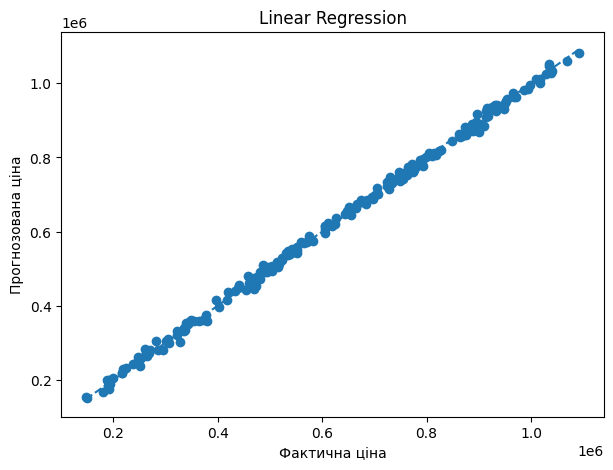

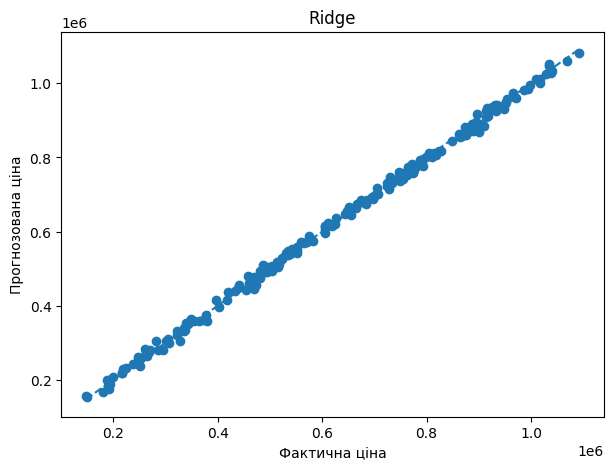

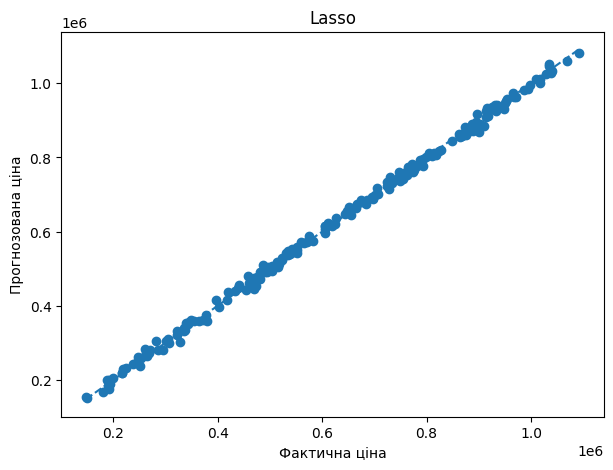

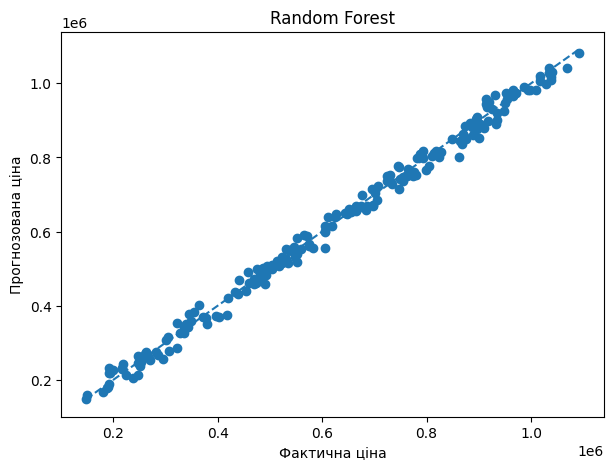

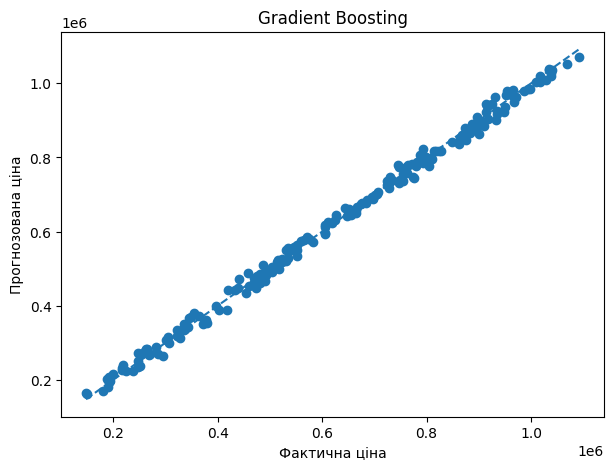

In [29]:
# Ваш код:
# Побудуйте окремий графік для кожної моделі.

for name, y_pred in predictions.items():
    plt.figure(figsize=(7, 5))

    plt.scatter(y_test, y_pred)

    plt.plot(
        [y_test.min(), y_test.max()],
        [y_test.min(), y_test.max()],
        linestyle="--"
    )

    plt.xlabel("Фактична ціна")
    plt.ylabel("Прогнозована ціна")
    plt.title(name)

    plt.show()



## 8. Підбір гіперпараметрів Random Forest

### Завдання 17. GridSearchCV
Виконайте підбір оптимальних параметрів для `RandomForestRegressor` за допомогою `GridSearchCV`.

Дослідіть щонайменше такі параметри:
- `n_estimators`;
- `max_features`;
- `max_depth`;
- `min_samples_split`.

Використайте крос-валідацію та метрику `R²`.

In [31]:
# Ваш код:
# Створіть сітку параметрів, GridSearchCV і знайдіть найкращі параметри.
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [50, 100, 200],
    "max_features": ["sqrt", 1.0],
    "max_depth": [None, 10, 20],
    "min_samples_split": [2, 5]
}
grid_search = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Найкращі параметри:")
print(grid_search.best_params_)

print("Найкращий R² на крос-валідації:")
print(grid_search.best_score_)

Найкращі параметри:
{'max_depth': None, 'max_features': 1.0, 'min_samples_split': 2, 'n_estimators': 200}
Найкращий R² на крос-валідації:
0.9919663079158397


### Завдання 18. Оптимізована модель Random Forest
Створіть нову модель з найкращими параметрами, навчіть її та обчисліть `R²`, `MAE`, `MSE` на тестовій вибірці.

In [32]:
# Ваш код:
# Навчіть оптимізований Random Forest та обчисліть метрики.

optimized_rf = RandomForestRegressor(
    **grid_search.best_params_,
    random_state=42
)

optimized_rf.fit(X_train, y_train)

y_pred_optimized = optimized_rf.predict(X_test)

optimized_r2 = r2_score(y_test, y_pred_optimized)
optimized_mae = mean_absolute_error(y_test, y_pred_optimized)
optimized_mse = mean_squared_error(y_test, y_pred_optimized)

print("R²:", optimized_r2)
print("MAE:", optimized_mae)
print("MSE:", optimized_mse)

R²: 0.9939926162295505
MAE: 16035.16807954079
MSE: 387229091.9214415


### Завдання 19. Порівняння Random Forest до і після оптимізації
Порівняйте значення `R²`, `MAE` і `MSE` для базової та оптимізованої моделей.

In [33]:
# Ваш код:
# Виведіть результати двох моделей у зручному для порівняння вигляді.

base_rf = results_df[
    results_df["Model"] == "Random Forest"
].iloc[0]

comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "Optimized Random Forest"
    ],
    "R²": [
        base_rf["R²"],
        optimized_r2
    ],
    "MAE": [
        base_rf["MAE"],
        optimized_mae
    ],
    "MSE": [
        base_rf["MSE"],
        optimized_mse
    ]
})

comparison

,Model,R²,MAE,MSE
0,Random Forest,0.993886,16114.289644,3.941317e+08
1,Optimized Random Forest,0.993993,16035.168080,3.872291e+08


### Завдання 20. Аналіз оптимізації
Зробіть короткий висновок:
- чи покращилася якість моделі після підбору параметрів;
- які метрики змінилися;
- чи доцільно використовувати оптимізовану модель.

**Ваш висновок:**

Після підбору гіперпараметрів якість моделі Random Forest трохи покращилася. Значення R² збільшилося з 0.993886 до 0.993993, MAE зменшилося з 16114.29 до 16035.17, а MSE — з 3.941317×10⁸ до 3.872291×10⁸. Отже, оптимізована модель дає трохи точніші прогнози, тому її використання є доцільним, хоча покращення є незначним.

## 9. Аналіз прогнозів лінійної регресії

### Завдання 21. Таблиця прогнозів
Для моделі Linear Regression створіть таблицю з трьома стовпцями:
- фактична ціна;
- прогнозована ціна;
- похибка у відсотках.

Виведіть 10 випадкових рядків.

In [35]:
# Ваш код:
# Сформуйте DataFrame з фактичними та прогнозованими значеннями і розрахуйте похибку у %.
predictions["Linear Regression"]


linear_predictions = pd.DataFrame({
    "Actual_Price": y_test.values,
    "Predicted_Price": predictions["Linear Regression"]
})

linear_predictions["Error_Percent"] = (
    abs(
        linear_predictions["Actual_Price"]
        - linear_predictions["Predicted_Price"]
    )
    / linear_predictions["Actual_Price"]
    * 100
)

linear_predictions.sample(10, random_state=42)

,Actual_Price,Predicted_Price,Error_Percent
95,1.068538e+06,1.059729e+06,0.824406
15,1.943537e+05,1.878686e+05,3.336793
30,2.702306e+05,2.797158e+05,3.510031
158,9.860069e+05,9.819493e+05,0.411517
128,9.533397e+05,9.573829e+05,0.424111
115,9.145557e+05,9.097643e+05,0.523912
69,7.461677e+05,7.424691e+05,0.495678
170,6.467663e+05,6.544456e+05,1.187332
174,5.233231e+05,5.246054e+05,0.245045
45,1.008539e+06,1.011344e+06,0.278073


## 10. Висновки
Сформулюйте загальний висновок за результатами лабораторної роботи. Вкажіть:

1. Які моделі було побудовано.
2. Яка модель показала найкращі значення метрик.
3. Як вплинув підбір гіперпараметрів Random Forest.
4. Наскільки точними є прогнози на тестовій вибірці.
5. Які фактори можуть впливати на якість прогнозування ціни нерухомості.

**Загальний висновок:**

У лабораторній роботі було проведено аналіз даних про вартість нерухомості та побудовано п’ять моделей регресії: Linear Regression, Ridge, Lasso, Random Forest Regressor та Gradient Boosting Regressor.  
Найкращі результати показала модель Linear Regression з коефіцієнтом детермінації R² = 0.998426, середньою абсолютною похибкою MAE = 8174.58 та MSE = 1.014348×10⁸. Дуже близькі результати також показала модель Lasso.  
Для Random Forest було виконано підбір гіперпараметрів за допомогою GridSearchCV. Після оптимізації R² збільшився з 0.993886 до 0.993993, MAE зменшився з 16114.29 до 16035.17, а MSE — з 3.941317×10⁸ до 3.872291×10⁸. Отже, оптимізація трохи покращила модель, однак Random Forest все одно поступається Linear Regression за якістю прогнозування.
Прогнози Linear Regression на тестовій вибірці є досить точними. У 10 випадково вибраних прикладах відсоткова похибка становила приблизно від 0.25% до 3.51%, а більшість прогнозів були дуже близькими до фактичних значень.
На якість прогнозування вартості нерухомості можуть впливати характеристики будинку, зокрема його площа, кількість кімнат і ванних кімнат, рік побудови, розмір ділянки та гаража, а також якість району. За результатами роботи лінійні моделі найкраще описують залежності у даному датасеті.